In [5]:
import pandas as pd
import matplotlib.pyplot as plt

def lire(nom):
    return pd.read_csv(f"data/clean/{nom}.csv", encoding="utf-8-sig")

h = lire("ventes_horaire");    h = h[h["heure_ouverture"]]
j = lire("ventes_journalier"); j = j[j["journee_complete"]]
s = lire("ventes_hebdo");      s = s[s["semaine_complete"]]
m = lire("ventes_mensuel");    m = m[m["mois_complet"]]

niveaux = {"Heure": h, "Jour": j, "Semaine": s, "Mois": m}
sensibles = [c for c in j.columns if c.endswith("(N05B)") or c.endswith("(N05C)")]



In [6]:
SEUIL = 2   # une periode est "isolee" si elle compte 2 unites ou moins

lignes = {}
for nom, df in niveaux.items():
    lignes[nom] = {}
    for c in sensibles:
        ventes = df[c][df[c] > 0]                 # periodes avec au moins une vente
        lignes[nom][c] = 100 * (ventes <= SEUIL).mean()
isole = pd.DataFrame(lignes).T
display(isole.round(1))


,Anxiolytiques (N05B),Somnifères (N05C)
Heure,81.7,85.8
Jour,6.9,75.4
Semaine,0.0,21.5
Mois,0.0,0.0


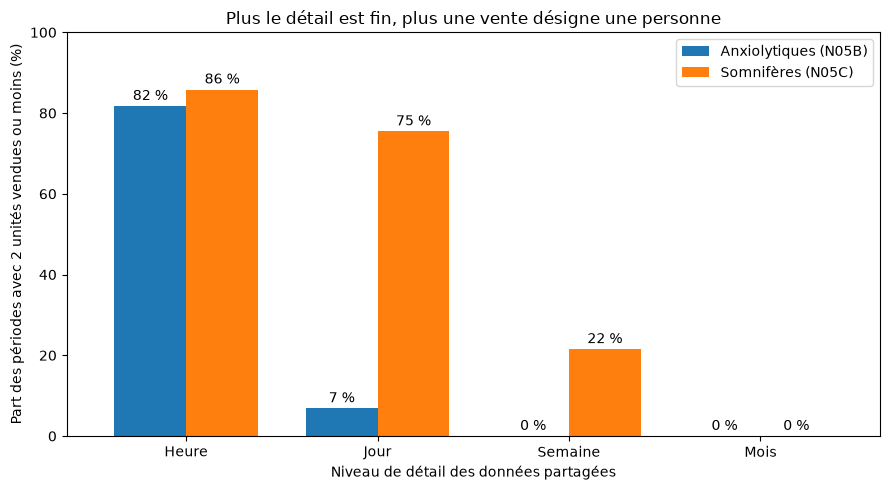

In [7]:
ax = isole.plot(kind="bar", figsize=(9, 5), rot=0, width=0.75)
ax.set_ylabel("Part des périodes avec 2 unités vendues ou moins (%)")
ax.set_xlabel("Niveau de détail des données partagées")
ax.set_ylim(0, 100)
ax.set_title("Plus le détail est fin, plus une vente désigne une personne")
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.0f %%", padding=2)
plt.tight_layout()
plt.savefig("graphique_partage.png", dpi=150)
plt.show()
